# Comparação entre classificadores

Lê os resultados salvos pelos notebooks de classificação (`resultados/<versão>/<classificador>.csv`). Execute-os antes deste notebook.

In [11]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

from pathlib import Path

import pandas as pd
import seaborn as sns
from avaliacao import SPLITS

pd.set_option("display.max_rows", 200)

res = pd.concat([pd.read_csv(f).assign(versao=f.parent.name, classificador=f.stem)
                 for f in sorted(Path("resultados").glob("*/*.csv"))], ignore_index=True)
chave = ["versao", "classificador", "modelo"]
res.groupby(["versao", "classificador"]).size().rename("registros").to_frame()

registros
versao                     classificador                               
classification             distancia_minima_centroide               500
                           distancia_minima_centroide_robust        500
                           max_correlacao                           500
classification_sklearn     distancia_minima_centroide               500
                           distancia_minima_centroide_robust        500
                           max_correlacao                           500
                           vizinho_mais_prox                       3000
classification_sklearn_raw distancia_minima_centroide               500
                           distancia_minima_centroide_robust        500
                           max_correlacao                           500
                           vizinho_mais_prox                       3000

## Acurácia média por separação treino/teste

In [12]:
res.pivot_table(index=chave, columns="split", values="acuracia", aggfunc="mean")[list(SPLITS)].round(4)

split                                                                            20/80  \
versao                     classificador                     modelo                      
classification             distancia_minima_centroide        DMC                0.6088   
                           distancia_minima_centroide_robust DMC robusto        0.7599   
                           max_correlacao                    Máxima correlação  0.5775   
classification_sklearn     distancia_minima_centroide        DMC                0.7371   
                           distancia_minima_centroide_robust DMC robusto        0.8146   
                           max_correlacao                    Máxima correlação  0.7053   
                           vizinho_mais_prox                 m = 1              0.9507   
                                                             m = 1/2            0.9489   
                                                             m = 2              0.9489   
                                                             m = 2/3            0.9498   
                                                             m = 3/2            0.9500   
                                                             m = 5/2            0.9481   
classification_sklearn_raw distancia_minima_centroide        DMC                0.6088   
                           distancia_minima_centroide_robust DMC robusto        0.7599   
                           max_correlacao                    Máxima correlação  0.5775   
                           vizinho_mais_prox                 m = 1              0.9471   
                                                             m = 1/2            0.9462   
                                                             m = 2              0.9448   
                                                             m = 2/3            0.9467   
                                                             m = 3/2            0.9462   
                                                             m = 5/2            0.9440   

split                                                                            30/70  \
versao                     classificador                     modelo                      
classification             distancia_minima_centroide        DMC                0.6078   
                           distancia_minima_centroide_robust DMC robusto        0.7585   
                           max_correlacao                    Máxima correlação  0.5789   
classification_sklearn     distancia_minima_centroide        DMC                0.7408   
                           distancia_minima_centroide_robust DMC robusto        0.8168   
                           max_correlacao                    Máxima correlação  0.7062   
                           vizinho_mais_prox                 m = 1              0.9596   
                                                             m = 1/2            0.9585   
                                                             m = 2              0.9582   
                                                             m = 2/3            0.9594   
                                                             m = 3/2            0.9592   
                                                             m = 5/2            0.9577   
classification_sklearn_raw distancia_minima_centroide        DMC                0.6078   
                           distancia_minima_centroide_robust DMC robusto        0.7585   
                           max_correlacao                    Máxima correlação  0.5789   
                           vizinho_mais_prox                 m = 1              0.9569   
                                                             m = 1/2            0.9560   
                                                             m = 2              0.9551   
                                                             m = 2/3            0.9564   
                                       

## Tempos médios de treinamento e teste (ms)

In [13]:
res.groupby(chave)[["t_treino_ms", "t_teste_ms"]].mean().round(4)

t_treino_ms  \
versao                     classificador                     modelo                           
classification             distancia_minima_centroide        DMC                     0.3059   
                           distancia_minima_centroide_robust DMC robusto             0.8242   
                           max_correlacao                    Máxima correlação       0.3048   
classification_sklearn     distancia_minima_centroide        DMC                     1.8907   
                           distancia_minima_centroide_robust DMC robusto             2.3860   
                           max_correlacao                    Máxima correlação       2.1892   
                           vizinho_mais_prox                 m = 1                   1.0599   
                                                             m = 1/2                 1.0804   
                                                             m = 2                   1.0408   
                                                             m = 2/3                 1.0924   
                                                             m = 3/2                 1.0399   
                                                             m = 5/2                 1.0732   
classification_sklearn_raw distancia_minima_centroide        DMC                     2.7789   
                           distancia_minima_centroide_robust DMC robusto             3.2521   
                           max_correlacao                    Máxima correlação       3.0916   
                           vizinho_mais_prox                 m = 1                   1.6078   
                                                             m = 1/2                 1.6641   
                                                             m = 2                   1.6079   
                                                             m = 2/3                 1.6748   
                                                             m = 3/2                 1.5866   
                                                             m = 5/2                 1.6434   

                                                                                t_teste_ms  
versao                     classificador                     modelo                         
classification             distancia_minima_centroide        DMC                    0.4059  
                           distancia_minima_centroide_robust DMC robusto            0.6306  
                           max_correlacao                    Máxima correlação      0.1438  
classification_sklearn     distancia_minima_centroide        DMC                    2.5878  
                           distancia_minima_centroide_robust DMC robusto            1.3071  
                           max_correlacao                    Máxima correlação      0.1678  
                           vizinho_mais_prox                 m = 1                 12.0633  
                                                             m = 1/2              107.0042  
                                                             m = 2                  8.0644  
                                                             m = 2/3              107.1987  
                                                             m = 3/2              106.4771  
                                                             m = 5/2              106.4073  
classification_sklearn_raw distancia_minima_centroide        DMC                    3.8868  
                           distancia_minima_centroide_robust DMC robusto            1.7420  
                           max_correlacao                    Máxima correlação      0.2349  
                           vizinho_mais_prox                 m = 1                 18.0751  
                                                             m = 1/2              162.2933  
                                                             m = 2                 12.3452  
                                  

## Ranking no split 80/20

In [14]:
ranking = (res[res["split"] == "80/20"].groupby(chave)
           .agg(acuracia=("acuracia", "mean"), desvio=("acuracia", "std"), t_teste_ms=("t_teste_ms", "mean"))
           .sort_values("acuracia", ascending=False))
ranking.round(4)

acuracia  \
versao                     classificador                     modelo                        
classification_sklearn     vizinho_mais_prox                 m = 2/3              0.9737   
                                                             m = 1                0.9730   
                                                             m = 1/2              0.9730   
                                                             m = 3/2              0.9729   
                                                             m = 5/2              0.9725   
                                                             m = 2                0.9725   
classification_sklearn_raw vizinho_mais_prox                 m = 2/3              0.9717   
                                                             m = 1                0.9716   
                                                             m = 3/2              0.9716   
                                                             m = 2                0.9711   
                                                             m = 1/2              0.9710   
                                                             m = 5/2              0.9704   
classification_sklearn     distancia_minima_centroide_robust DMC robusto          0.8205   
classification_sklearn_raw distancia_minima_centroide_robust DMC robusto          0.7556   
classification             distancia_minima_centroide_robust DMC robusto          0.7556   
classification_sklearn     distancia_minima_centroide        DMC                  0.7445   
                           max_correlacao                    Máxima correlação    0.7051   
classification_sklearn_raw distancia_minima_centroide        DMC                  0.6019   
classification             distancia_minima_centroide        DMC                  0.6019   
                           max_correlacao                    Máxima correlação    0.5700   
classification_sklearn_raw max_correlacao                    Máxima correlação    0.5700   

                                                                                desvio  \
versao                     classificador                     modelo                      
classification_sklearn     vizinho_mais_prox                 m = 2/3            0.0038   
                                                             m = 1              0.0042   
                                                             m = 1/2            0.0040   
                                                             m = 3/2            0.0043   
                                                             m = 5/2            0.0045   
                                                             m = 2              0.0046   
classification_sklearn_raw vizinho_mais_prox                 m = 2/3            0.0044   
                                                             m = 1              0.0045   
                                                             m = 3/2            0.0045   
                                                             m = 2              0.0049   
                                                             m = 1/2            0.0044   
                                                             m = 5/2            0.0050   
classification_sklearn     distancia_minima_centroide_robust DMC robusto        0.0094   
classification_sklearn_raw distancia_minima_centroide_robust DMC robusto        0.0153   
classification             distancia_minima_centroide_robust DMC robusto        0.0153   
classification_sklearn     distancia_minima_centroide        DMC                0.0120   
                           max_correlacao                    Máxima correlação  0.0130   
classification_sklearn_raw distancia_minima_centroide        DMC                0.0132   
classification             distancia_minima_centroide        DMC                0.0132   
                           max_correlacao                    Máxima corre

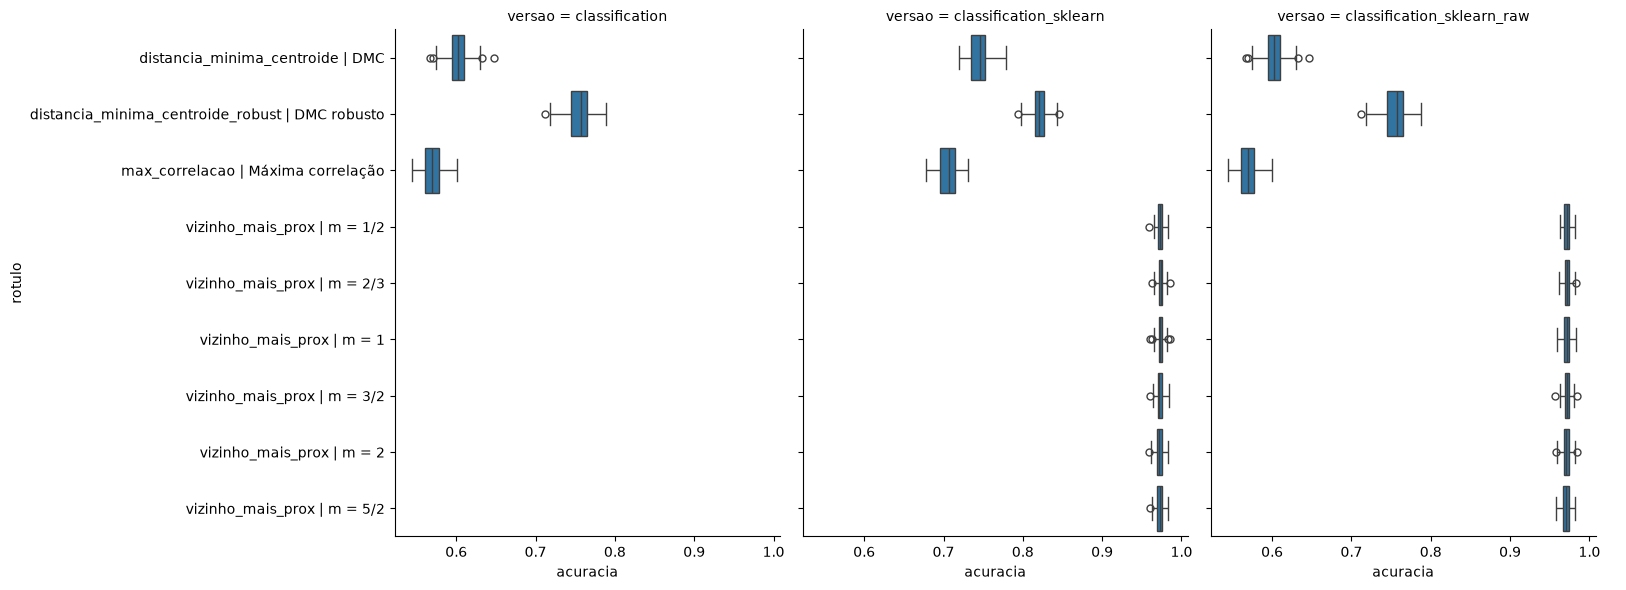

In [15]:
res["rotulo"] = res["classificador"] + " | " + res["modelo"]
sns.catplot(res[res["split"] == "80/20"], x="acuracia", y="rotulo", col="versao", kind="box", height=6, aspect=0.9);

## Gráficos de comparação — acurácia média (scikit-learn: base original × base processada)

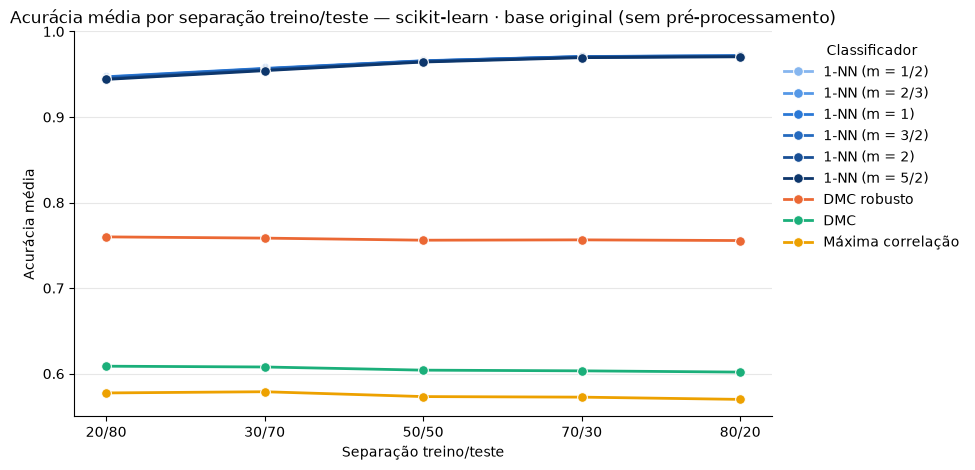

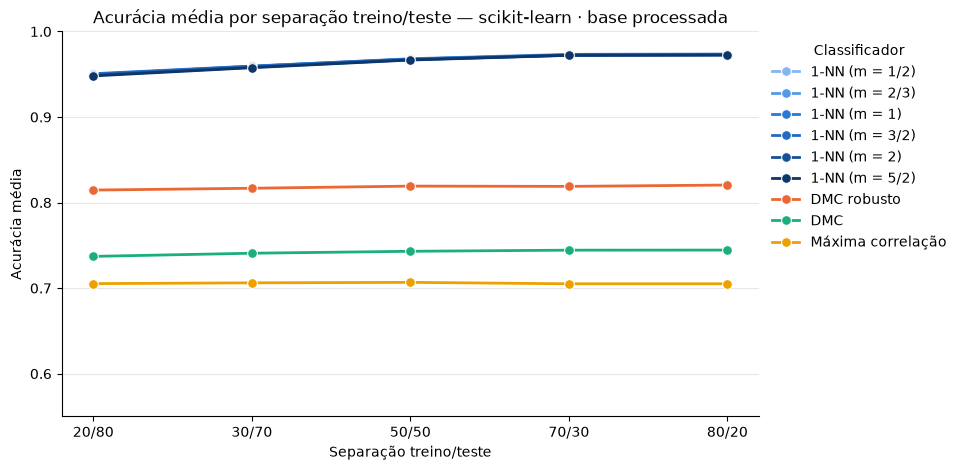

In [16]:
import matplotlib.pyplot as plt

NOMES = {"distancia_minima_centroide": "DMC", "distancia_minima_centroide_robust": "DMC robusto",
         "max_correlacao": "Máxima correlação"}
VERSOES = {"classification_sklearn_raw": "scikit-learn · base original (sem pré-processamento)",
           "classification_sklearn": "scikit-learn · base processada"}
# 1-NN: tons de azul do m menor para o maior; demais classificadores: cores próprias
ORDENS = ["1/2", "2/3", "1", "3/2", "2", "5/2"]
CORES = {f"1-NN (m = {m})": c for m, c in zip(ORDENS, ["#86b6ef", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"])}
CORES |= {"DMC robusto": "#eb6834", "DMC": "#1baf7a", "Máxima correlação": "#eda100"}

media = (res[res["versao"].isin(VERSOES)]
         .assign(nome=lambda d: d["classificador"].map(NOMES).fillna("1-NN (" + d["modelo"] + ")"))
         .groupby(["versao", "nome", "split"], as_index=False)["acuracia"].mean())
ylim = (media["acuracia"].min() - 0.02, 1)  # mesma escala nos dois gráficos

for versao, titulo in VERSOES.items():
    dados = media[media["versao"] == versao]
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.lineplot(dados, x="split", y="acuracia", hue="nome", palette=CORES,
                 hue_order=[n for n in CORES if n in set(dados["nome"])],
                 marker="o", markersize=7, linewidth=2, ax=ax)
    ax.set(title=f"Acurácia média por separação treino/teste — {titulo}",
           xlabel="Separação treino/teste", ylabel="Acurácia média", ylim=ylim)
    ax.grid(axis="y", alpha=0.3)
    sns.despine()
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="Classificador", frameon=False)
    plt.show()

## Melhor modelo de cada versão

In [17]:
for versao, g in ranking.reset_index().groupby("versao"):
    top = g.iloc[0]
    print(f"{versao}: {top['classificador']} ({top['modelo']}) -> acurácia {top['acuracia']:.4f} ± {top['desvio']:.4f}, "
          f"teste em {top['t_teste_ms']:.2f} ms")

classification: distancia_minima_centroide_robust (DMC robusto) -> acurácia 0.7556 ± 0.0153, teste em 0.31 ms
classification_sklearn: vizinho_mais_prox (m = 2/3) -> acurácia 0.9737 ± 0.0038, teste em 106.18 ms
classification_sklearn_raw: vizinho_mais_prox (m = 2/3) -> acurácia 0.9717 ± 0.0044, teste em 256.74 ms
